In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, rand_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [2]:
df = pd.read_csv('workshops/5/fma_dataset_filtered.csv')
print(f"Initial shape: {df.shape}")
df.head()

Initial shape: (2406, 524)


,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy,genre
0,2,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593,2.691455,0.866868,...,0.085629,0.071289,0.000000,2.089872,0.061448,168,165.922,0.675894,0.634476,Hip-Hop
1,3,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848,1.054094,0.108103,...,0.084578,0.063965,0.000000,1.716724,0.069330,237,126.957,0.528643,0.817461,Hip-Hop
2,5,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192,-0.927232,0.666617,...,0.053114,0.041504,0.000000,2.193303,0.044861,206,100.260,0.745566,0.701470,Hip-Hop
3,134,0.918445,0.674147,0.577818,1.281117,0.933746,0.078177,1.199204,-0.175223,0.925482,...,0.064370,0.050781,0.000000,1.806106,0.054623,207,114.290,0.513238,0.560410,Hip-Hop
4,139,-0.020869,0.432330,0.331278,0.829845,2.625593,2.005660,0.907704,0.748191,1.560385,...,0.070760,0.066895,0.000977,0.769163,0.030017,296,196.961,0.260911,0.607067,Folk


In [3]:
print(f"Missing values: {df.isna().sum().sum()}, Duplicates: {df.duplicated().sum()}")

df = df.drop(columns=['track_id'], errors='ignore').dropna().drop_duplicates().reset_index(drop=True)
print(f"Shape after cleaning: {df.shape}")
print("\nGenre distribution:")
print(df['genre'].value_counts())

y = df['genre']
X = df.drop(columns=['genre'])

Missing values: 0, Duplicates: 0
Shape after cleaning: (2406, 523)

Genre distribution:
genre
Hip-Hop                910
Folk                   874
Old-Time / Historic    357
Classical              265
Name: count, dtype: int64


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [6]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

In [7]:
tsne_2d = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne_2d.fit_transform(X_scaled)

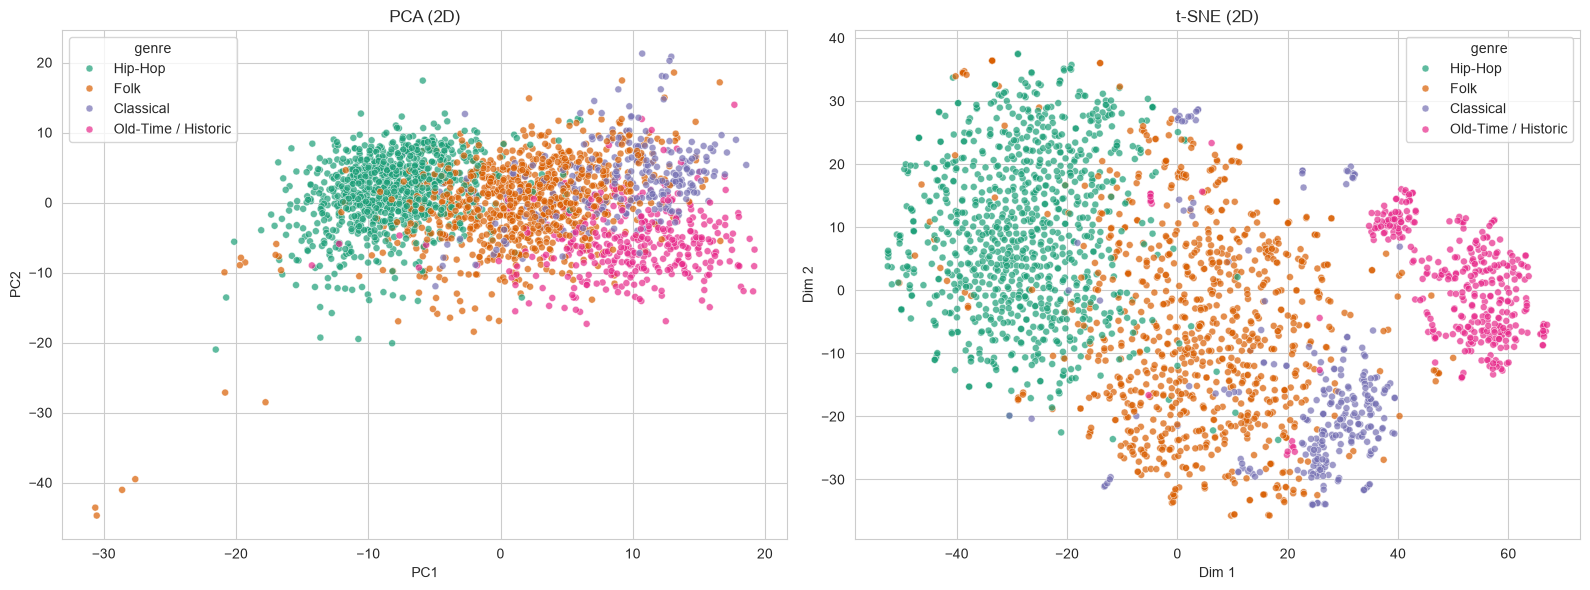

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='Dark2', alpha=0.7, s=25, ax=axes[0])
axes[0].set_title('PCA (2D)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette='Dark2', alpha=0.7, s=25, ax=axes[1])
axes[1].set_title('t-SNE (2D)')
axes[1].set_xlabel('Dim 1')
axes[1].set_ylabel('Dim 2')

plt.tight_layout()
plt.show()

In [9]:
pca_full = PCA(random_state=42).fit(X_scaled)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_) * 100
var_2_comp = cum_variance[1]
print(f'Explained variance (2 components): {var_2_comp:.2f}%')

Explained variance (2 components): 21.64%


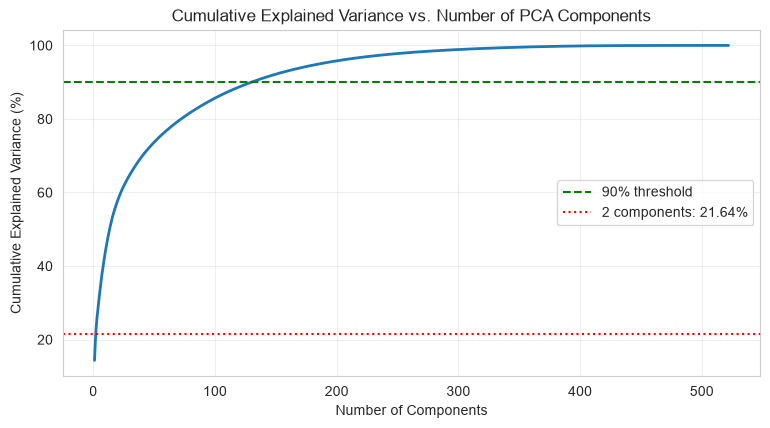

In [10]:
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, linewidth=2)
plt.axhline(y=90, color='green', linestyle='--', label='90% threshold')
plt.axhline(y=var_2_comp, color='red', linestyle=':', label=f'2 components: {var_2_comp:.2f}%')
plt.title('Cumulative Explained Variance vs. Number of PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
k_values = range(2, 7)
sil_scores, ri_scores, ari_scores = [], [], []

for k in k_values:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))
    ri_scores.append(rand_score(y_encoded, labels))
    ari_scores.append(adjusted_rand_score(y_encoded, labels))

metrics_df = pd.DataFrame({
    'k': list(k_values),
    'Silhouette': sil_scores,
    'Rand Index': ri_scores,
    'Adjusted Rand Index': ari_scores
})
metrics_df

,k,Silhouette,Rand Index,Adjusted Rand Index
0,2,0.109617,0.680312,0.360527
1,3,0.089893,0.785551,0.527104
2,4,0.075633,0.773980,0.454473
3,5,0.071848,0.804683,0.507060
4,6,0.072137,0.804779,0.506193


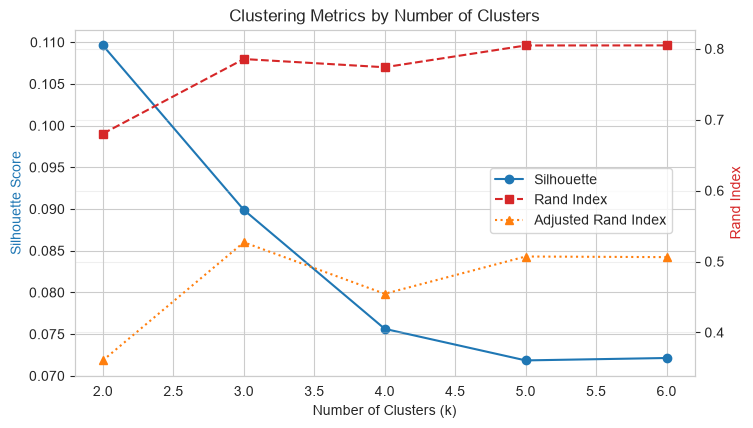

In [12]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(k_values, sil_scores, 'o-', color='tab:blue', label='Silhouette')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Silhouette Score', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(k_values, ri_scores, 's--', color='tab:red', label='Rand Index')
ax2.plot(k_values, ari_scores, '^:', color='tab:orange', label='Adjusted Rand Index')
ax2.set_ylabel('Rand Index', color='tab:red')

fig.legend(loc='center right', bbox_to_anchor=(0.88, 0.5))
plt.title('Clustering Metrics by Number of Clusters')
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
best_k = int(metrics_df.loc[metrics_df['Adjusted Rand Index'].idxmax(), 'k'])
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(X_scaled)

centroid_std = pd.DataFrame(km_best.cluster_centers_, columns=X.columns).std().sort_values(ascending=False)
centroid_std.head(10)

mfcc_mean_04      1.165629
mfcc_median_04    1.154853
mfcc_max_04       1.135888
mfcc_mean_08      1.117996
mfcc_median_08    1.116982
mfcc_max_03       1.077669
mfcc_mean_07      1.077614
mfcc_median_07    1.077451
mfcc_mean_06      1.059896
mfcc_max_08       1.056055
dtype: float64

### 6.1. Whether visualization results from p.3 reflects the real distribution of the genres? Which algorithm performs better and why?

The 2D plots reflect the actual genre distribution only partially. Hip-Hop, Old-Time / Historic, and Classical form fairly distinct areas, whereas Folk overlaps noticeably with the rest because it shares acoustic characteristics with other styles and projecting 522 features onto 2 dimensions loses almost 80% of the variance.

t-SNE performs noticeably better than PCA here. Because PCA is a linear projection focused on maximizing global variance, all four genres end up overlapping in one dense cloud near the center. t-SNE is non-linear and preserves local neighborhood similarities, which allows it to separate Hip-Hop, Classical, and Old-Time / Historic into distinct clusters.

### 6.2. What percentage of the explained variance was left after we have excluded all but 2 components in p.4?

Keeping only the first 2 principal components leaves 21.64% of the total explained variance (meaning 78.36% of the variance is lost in the 2D projection).

### 6.3. Can Silhouette metric be chosen as optimal criteria for the number of clusters for that data? Is Rand Index more appropriate?

The Silhouette metric is not a good criterion for choosing the number of clusters on this dataset. In a 522-dimensional feature space, audio tracks form a continuous, non-spherical distribution without clear geometric gaps, so Silhouette simply peaks at the smallest tested value $k = 2$ (0.110) and decreases as $k$ grows, missing the true 4-genre structure.

Rand Index is much more appropriate when ground-truth genre labels are available, as it directly measures how well the clustering matches actual genres. Looking at raw Rand Index alone, the score rises monotonically with $k$ and reaches its maximum at $k = 6$ (0.805) because larger $k$ increases random pair agreements. Using Adjusted Rand Index (ARI) corrects for chance and gives a clearer optimum at $k = 3$ (0.527), which aligns with the 3 well-separated genre clusters seen in the t-SNE plot.

### 6.4. If you don't know the genre but need to build a song recommendation system based on the similarity between the songs in this dataset - what would you do?

Without genre labels, I would build a content-based similarity pipeline using the audio features. First, I would drop `track_id`, remove near-duplicate correlated features, and standardize the remaining features with `StandardScaler`. Next, I would apply PCA retaining around 90-95% of the variance (roughly 130-200 components) to filter out high-dimensional noise and speed up distance computations. Finally, for any query track, I would compute cosine similarity (or Euclidean distance on L2-normalized vectors) against all other songs and recommend the top-$N$ nearest neighbors.

### 6.5*. How do you think, what is the most important feature (from the initial dataset) for the cluster division?

Based on the standard deviation of feature values across the cluster centroids, the most influential features for separating clusters are mid-range MFCC statistics — specifically `mfcc_mean_04`, `mfcc_median_04`, `mfcc_max_04`, `mfcc_mean_08`, and `mfcc_median_08` (along with `mfcc_max_03` and `mfcc_mean_07`). Since MFCCs capture the shape of the short-term power spectrum, these coefficients reflect key timbral and instrumentation differences (such as vocals, percussion, and acoustic vs. electronic textures) that distinguish genres like Hip-Hop, Classical, and Old-Time / Historic.